# 01 - Telco EDA - training customers only

Explore the persisted training membership, never choose models from held-out test data.
`customerID` identifies records; `Churn` is the target and neither is an input feature.
No model or preprocessing is fitted here. Missing numeric values remain missing.

Inputs: `config.yaml`, raw-data checksum, `data/splits/manifest.json`, `memberships.csv`, **train.csv only**.
The full raw CSV is hashed for provenance, not loaded for EDA. Run from the repository,
backend or notebooks directory with the environment in `requirements/notebooks.txt`.
See [setup and definitions](../../docs/NOTEBOOKS.md).

In [1]:
from pathlib import Path
import sys, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
BACKEND = next((p / "backend" if (p / "backend/config.yaml").exists() else p)
               for p in [here, *here.parents]
               if (p / "backend/config.yaml").exists() or (p / "config.yaml").exists() and (p / "src/opsyntra").exists())
sys.path.insert(0, str(BACKEND / "src"))
from opsyntra.ml.notebooks import Exports, verified_partition, model_reports, validation_scores, analytics_snapshot
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=["#285b46", "#a97c35", "#587b9e", "#915780", "#718d57", "#b36154", "#5c8c89"]),
                     "svg.hashsalt": "opsyntra"})
OUT = Exports(BACKEND, "01_telco_eda")
print("Export directory:", OUT.directory.relative_to(BACKEND).as_posix())

Export directory: reports/notebooks/01_telco_eda


In [2]:
train, manifest = verified_partition(BACKEND, "train", OUT)
assert train.customerID.is_unique
assert train.Churn.isin(["No", "Yes"]).all()
overview = pd.DataFrame([{"partition":"train", "customers":len(train), "columns":len(train.columns),
                          "churn_share":train.Churn.eq("Yes").mean(),
                          "missing_TotalCharges":int(train.TotalCharges.isna().sum()),
                          "source_sha256":manifest["source_sha256"], "membership_sha256":manifest["membership_sha256"]}])
display(OUT.table("overview", overview))

,partition,customers,columns,churn_share,missing_TotalCharges,source_sha256,membership_sha256
0,train,4225,21,0.265325,8,88be4b93fbe0cc83421af1c503794c97c342eca914c157...,b51f7b090312e8c727b11753dd740acdadad3e47d01c22...


## Missing TotalCharges policy

The source data has 11 blank `TotalCharges` values across all partitions. The table below
reports the training subset only. Keep these customers and preserve nulls; the saved ML
pipelines learn numeric median imputation inside each training/CV fold. Do not fill with a
full-dataset mean, zero, or a value learned from validation/test. These descriptive medians
are not a fitted preprocessing artifact.

,feature,missing_train,descriptive_train_median
0,SeniorCitizen,0,0.00
1,tenure,0,29.00
2,MonthlyCharges,0,70.55
3,TotalCharges,8,1422.10


,statistic,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,count,4225.000000,4225.000000,4225.000000,4217.000000
1,mean,0.161893,32.609467,65.075562,2313.167880
2,std,0.368397,24.506761,30.058205,2281.957028
3,min,0.000000,0.000000,18.400000,18.800000
4,25%,0.000000,9.000000,38.500000,416.300000
5,50%,0.000000,29.000000,70.550000,1422.100000
6,75%,0.000000,56.000000,89.900000,3824.200000
7,max,1.000000,72.000000,118.750000,8684.800000


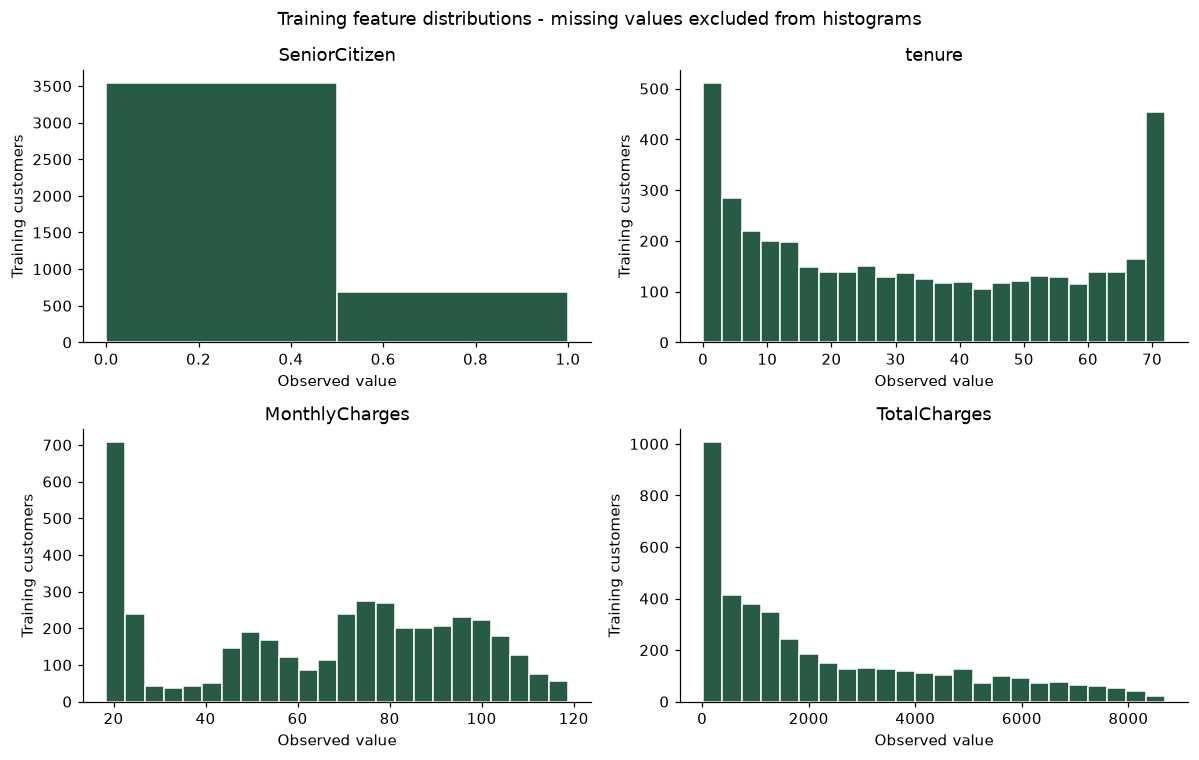

In [3]:
numeric = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
missing = pd.DataFrame({"feature":numeric, "missing_train":train[numeric].isna().sum().to_numpy(),
                        "descriptive_train_median":train[numeric].median().to_numpy()})
display(OUT.table("missing_values", missing))
display(OUT.table("numeric_summary", train[numeric].describe().rename_axis("statistic").reset_index()))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.flat, numeric):
    ax.hist(train[feature].dropna(), bins=2 if feature == "SeniorCitizen" else 24, edgecolor="white")
    ax.set(title=feature, xlabel="Observed value", ylabel="Training customers")
fig.suptitle("Training feature distributions - missing values excluded from histograms")
fig.tight_layout(); OUT.figure("numeric_distributions", fig); plt.show()

## Training class balance

Churn is the minority class. Accuracy alone can reward predicting No for everyone;
use recall, precision, F1, ROC-AUC and average precision alongside the dummy baseline.

,Churn,customers,share
0,No,3104,0.734675
1,Yes,1121,0.265325


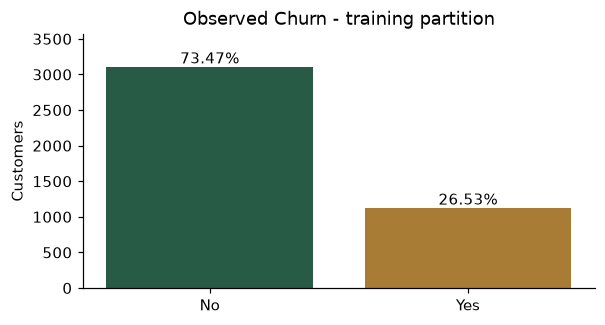

In [4]:
balance = train.Churn.value_counts().reindex(["No", "Yes"], fill_value=0).rename_axis("Churn").reset_index(name="customers")
balance["share"] = balance.customers / len(train)
display(OUT.table("class_balance", balance))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(balance.Churn, balance.customers, color=["#285b46", "#a97c35"])
for i, row in balance.iterrows(): ax.text(i, row.customers, f"{row.share:.2%}", ha="center", va="bottom")
ax.set(title="Observed Churn - training partition", ylabel="Customers"); ax.margins(y=.15)
OUT.figure("class_balance", fig); plt.show()

## Contract and tenure relationships

These are observed associations in the training sample, not causal effects. Display group
sizes with churn shares so small segments are not mistaken for strong evidence. A customer
can appear only once in this static training partition.

,Contract,customers,observed_churn_share,mean_tenure_months
0,Month-to-month,2305,0.431670,18.311931
1,One year,902,0.105322,41.470067
2,Two year,1018,0.030452,57.131631


,tenure_band,customers,observed_churn_share
0,0-12,1293,0.484145
1,13-24,602,0.292359
2,25-48,973,0.197328
3,49-72,1357,0.093589


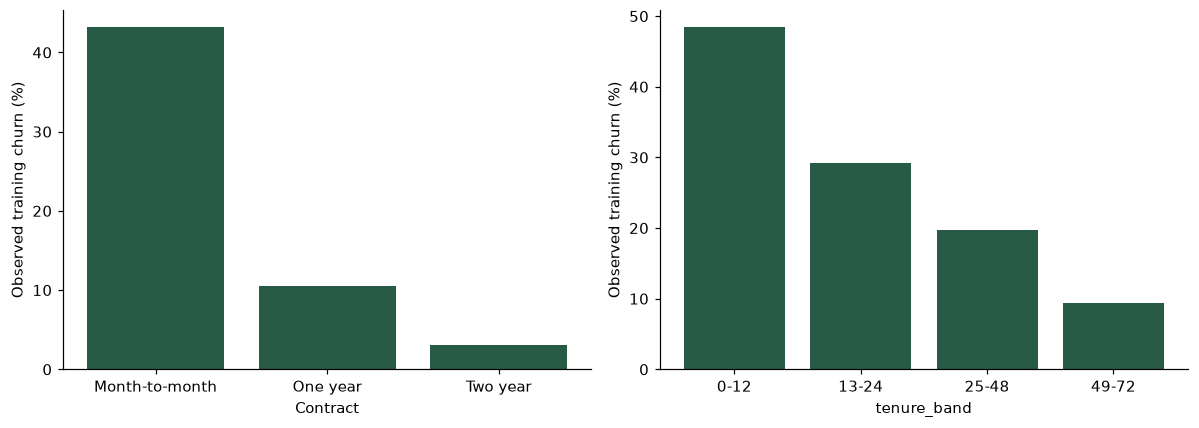

In [5]:
explore = train.assign(churned=train.Churn.eq("Yes"), tenure_band=pd.cut(train.tenure,
                 bins=[-1,12,24,48,72], labels=["0-12", "13-24", "25-48", "49-72"]))
contract = explore.groupby("Contract", observed=False).agg(customers=("customerID","size"),
                 observed_churn_share=("churned","mean"), mean_tenure_months=("tenure","mean")).reset_index()
tenure = explore.groupby("tenure_band", observed=False).agg(customers=("customerID","size"),
                 observed_churn_share=("churned","mean")).reset_index()
display(OUT.table("contract_summary", contract)); display(OUT.table("tenure_summary", tenure))
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, table, field in [(axes[0],contract,"Contract"),(axes[1],tenure,"tenure_band")]:
    ax.bar(table[field].astype(str), table.observed_churn_share * 100)
    ax.set(ylabel="Observed training churn (%)", xlabel=field)
fig.tight_layout(); OUT.figure("contract_tenure", fig); plt.show()

In [6]:
provenance = OUT.finish(partition="train", rows=len(train), held_out_feature_rows_read=0,
                        fitted_models=0, source_sha256=manifest["source_sha256"],
                        membership_sha256=manifest["membership_sha256"],
                        missing_policy="Preserve nulls; model pipelines fit training-only median imputation")
print("PASS: training-only tables and figures exported; input/output hashes saved.")

PASS: training-only tables and figures exported; input/output hashes saved.
